In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.special as scp

In [2]:
mu = 3 #1/hr
lamb = 12 #1/hr
T = 500 #hr
time = 0
n = 0
spent_time = np.zeros(1)
print(spent_time)

[0.]


In [3]:
while (time < T):
  wait = np.random.exponential(1/(lamb+n*mu))
  time += wait
  prob = lamb/(lamb+n*mu)
  check = np.random.rand()
  if (n>len(spent_time)-1):
    spent_time = np.append(spent_time, [wait])
  else:
    spent_time[n] += wait
  if (check <= prob):
    n += 1
  elif (n>0):
    n -= 1

N = len(spent_time) - 1 #largest state visited


In [4]:
states = np.arange(0, N+1)
fraction = spent_time/T
poissprobs = np.exp(-lamb/mu)*(lamb/mu)**states/(scp.factorial(states))

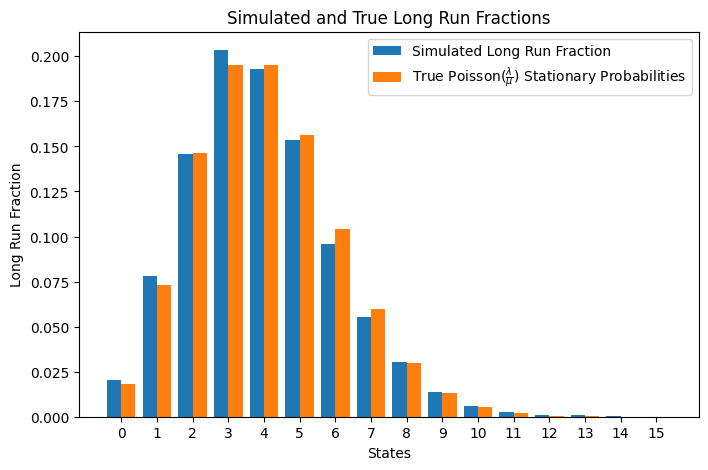

In [9]:
fig, ax = plt.subplots(figsize=(8,5))
width = 0.4
ax.bar(states-width/2, fraction, width, label="Simulated Long Run Fraction")

ax.bar(states+width/2, poissprobs, width, label="True Poisson($\\frac{\\lambda}{\\mu}$) Stationary Probabilities")
ax.set_xticks(states)
ax.set_xlabel("States")
ax.set_ylabel("Long Run Fraction")
ax.set_title("Simulated and True Long Run Fractions")
ax.legend()
plt.show()

In [6]:
maxerror = max(np.abs(fraction-poissprobs))
print("The largest difference between observed long run fraction and theoritical probabilities was " + str(round(maxerror, 5)))

The largest difference between observed long run fraction and theoritical probabilities was 0.00841


In [7]:
timeavg = np.sum(fraction*states)
print("The time average of $X_t$ was found to be " + str(round(timeavg, 3)) + " vs the theoretical poisson mean of " + str(lamb/mu))

The time average of $X_t$ was found to be 3.962 vs the theoretical poisson mean of 4.0


In [8]:
c_poiss =  np.min(np.trim_zeros(np.where(poissprobs < 0.01, states, 0)))
c_sim = np.min(np.trim_zeros(np.where(fraction < 0.01, states, 0)))
print("The smallest fleet size c where the number of bikes wanted exceeded c was \n" + str(c_poiss) + " based on the theoretical long run fraction, and " + str(c_sim) + " based on the simulation.")

The smallest fleet size c where the number of bikes wanted exceeded c was 
10 based on the theoretical long run fraction, and 10 based on the simulation.
